# Horas de internet e ingreso laboral
¿Existe asociación entre horas de internet e ingreso laboral de los ocupados en Ecuador? **ENEMDU TIC, julio de 2025**.

## Población
Ocupados de 15 años o más en Ecuador. Se mantiene la muestra del EDA: usuarios diarios con ambas respuestas.
Julio es el mes de levantamiento; el ingreso corresponde a junio. Las conclusiones se limitan a este grupo.

## Variables
| Papel | Variable | Unidad |
|---|---|---|
| X | `pt3b`, con `pt3a=1` | Horas con referencia diaria; 0 significa menos de una hora. |
| Y | `ingrl` | Ingreso laboral mensual, USD. |

## Modelo
Poblacional: $Y_i=\beta_0+\beta_1X_i+u_i$.

Muestral: $\widehat Y_i=\widehat\beta_0+\widehat\beta_1X_i$, con $\widehat u_i=Y_i-\widehat Y_i$.

## Datos
Parquet de la limpieza; se conservan los filtros del EDA.

In [14]:
import pandas as pd
import statsmodels.api as sm
from data_loader import load_data
from slr_plots import plot_fit, plot_residuals, plot_influence

In [15]:
limpios = load_data('data_clean.parquet', revision='main')
aux = load_data('enemdu_persona_tics_2025_07.csv', revision='main')

In [16]:
aux = aux[['id_persona', 'periodo', 'p03', 'empleo', 'pt3a']].copy()
for col in ['id_persona', 'periodo', 'empleo', 'pt3a']:
    aux[col] = aux[col].astype('string').str.strip()
datos = limpios.merge(aux, on=['id_persona', 'periodo'], validate='one_to_one')

In [17]:
muestra = datos.loc[
    (datos['empleo'] == '1') & (datos['p03'] >= 15) & (datos['pt3a'] == '1')
].dropna(subset=['pt3b', 'ingrl']).copy()
print('Personas:', len(muestra))

Personas: 9881


## Estimación
MCO sin ponderar. EE por UPM para heterocedasticidad y dependencia interna; no reproducen todo el diseño muestral.

In [30]:
X = sm.add_constant(muestra['pt3b'].astype(float))
y = muestra['ingrl'].astype(float)
modelo = sm.OLS(y, X).fit(
    cov_type='cluster', cov_kwds={'groups': muestra['upm']}, use_t=True
)
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                  ingrl   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                  0.052
Method:                 Least Squares   F-statistic:                     268.1
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           7.11e-55
Time:                        12:02:05   Log-Likelihood:                -76700.
No. Observations:                9881   AIC:                         1.534e+05
Df Residuals:                    9879   BIC:                         1.534e+05
Df Model:                           1                                         
Covariance Type:              cluster                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        364.1483     11.352     32.079      0.0

In [19]:
resultados = pd.DataFrame({'Coeficiente': modelo.params, 'EE (UPM)': modelo.bse}).round(3)
resultados[['IC inferior', 'IC superior']] = modelo.conf_int().round(3)
resultados['t'] = modelo.tvalues.round(3)
resultados['p-valor'] = modelo.pvalues
resultados.index = ['Intercepto', 'Horas de internet']
display(resultados)
print(f'R²: {modelo.rsquared:.4f} | SER: USD {modelo.mse_resid**0.5:.2f}')

,Coeficiente,EE (UPM),IC inferior,IC superior,t,p-valor
Intercepto,364.148,11.352,341.878,386.418,32.079,2.418908e-166
Horas de internet,61.356,3.747,54.005,68.708,16.374,7.108672e-55


R²: 0.0519 | SER: USD 568.79


$\widehat Y=364,15+61,36X$. Se rechaza $H_0:\beta_1=0$ al 5%.
El EE mide incertidumbre del coeficiente; el SER, dispersión residual.

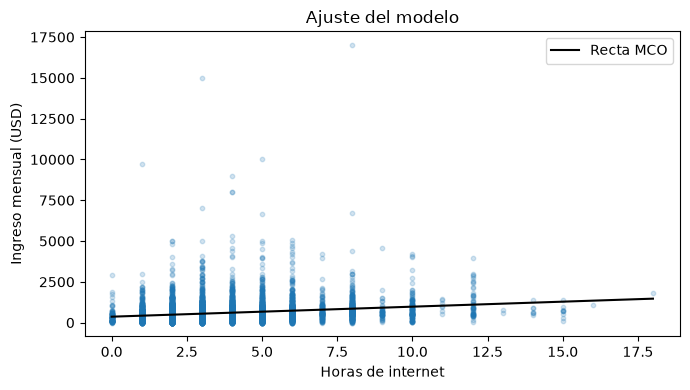

In [20]:
plot_fit(muestra, modelo)

## Tres horas más
$\Delta\widehat Y=\widehat\beta_1\Delta X$. Para $\Delta X>0$, se multiplican también los límites del intervalo.

In [21]:
delta = 3
print('Diferencia ajustada (USD):', round(delta * modelo.params['pt3b'], 2))
print('IC 95%:', (delta * modelo.conf_int().loc['pt3b']).round(2).tolist())

Diferencia ajustada (USD): 184.07
IC 95%: [162.02, 206.12]


**Ceteris paribus** sería causal si $E(u\mid X)=0$. Factores omitidos y causalidad inversa impiden justificarlo: aquí se estima asociación, no horas óptimas.

## Supuestos
| Supuesto | Evaluación |
|---|---|
| $E(u\mid X)=0$ | No comprobable con residuos; posibles factores omitidos. |
| i.i.d. | Poco realista: hogares y UPM compartidas. |
| Momentos cuartos finitos | No verificables en una muestra; revisar influencia. |
| Varianza constante | Evidencia de heterocedasticidad. |

In [22]:
display(muestra[['id_hogar', 'upm', 'estrato']].nunique().to_frame('Grupos'))
print('Varianza de X:', round(muestra['pt3b'].var(), 3))

,Grupos
id_hogar,6448
upm,1286
estrato,150


Varianza de X: 4.703


### Homocedasticidad
Se contrasta una tendencia de los residuos al cuadrado con X, usando EE por UPM.

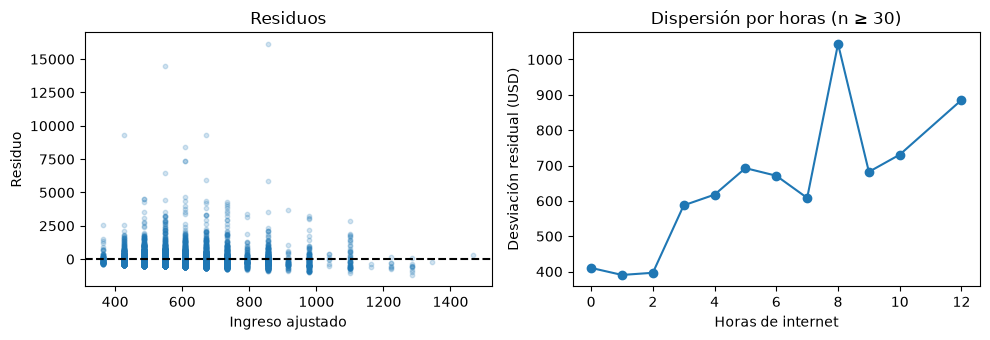

In [23]:
plot_residuals(muestra, modelo)

In [24]:
varianza = sm.OLS(modelo.resid**2, X).fit(
    cov_type='cluster', cov_kwds={'groups': muestra['upm']}, use_t=True
)
print('p-valor de la tendencia de varianza:', round(varianza.pvalues['pt3b'], 4))

p-valor de la tendencia de varianza: 0.006


**p = 0,006:** evidencia contra varianza constante. Se detecta una tendencia lineal, no todas las formas de heterocedasticidad.

### Extremos
Cook señala observaciones influyentes; no prueba errores ni justifica eliminarlas automáticamente.

,pt3b,ingrl,cook
21547,8,17000.0,0.228
21241,3,15000.0,0.034
24560,8,6745.0,0.030
2810,1,9700.0,0.029
7180,12,3972.0,0.022


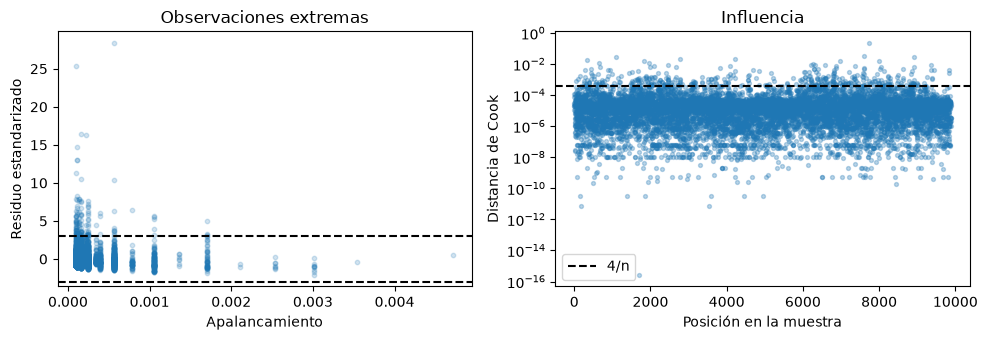

In [25]:
muestra['cook'] = modelo.get_influence().cooks_distance[0]
display(muestra.nlargest(5, 'cook')[['pt3b', 'ingrl', 'cook']].round(3))
plot_influence(modelo)

### Sensibilidad
Se repite el modelo sin Cook > 4/n como diagnóstico. La base limpia permanece intacta.

In [26]:
revision = muestra.loc[muestra['cook'] <= 4 / len(muestra)]
X_revision = sm.add_constant(revision['pt3b'].astype(float))
modelo_revision = sm.OLS(revision['ingrl'].astype(float), X_revision).fit(
    cov_type='cluster', cov_kwds={'groups': revision['upm']}, use_t=True
)
print('Pendiente revisada:', round(modelo_revision.params['pt3b'], 2))
display(modelo_revision.conf_int().loc[['pt3b']].rename(columns={0: 'IC inferior', 1: 'IC superior'}).round(2))

Pendiente revisada: 49.76


,IC inferior,IC superior
pt3b,46.14,53.38


## Conclusión
- Una hora se asocia con **USD 61,36**, IC 95% **[54,01; 68,71]**; tres horas, con **USD 184,07**, IC **[162,02; 206,12]**.
- R² = **5,19%**. Sin los casos marcados por Cook, la pendiente baja a **49,76**: es sensible a observaciones influyentes.
- No se identifica causalidad; exogeneidad e i.i.d. no están justificadas y hay heterocedasticidad.

## Fuentes
[ENEMDU TIC 2025](https://www.ecuadorencifras.gob.ec/documentos/web-inec/Estadisticas_Sociales/TIC/2025/202507_Formulario_ENEMDU_Julio_2025.pdf) · [Diseño de la encuesta](https://www.ecuadorencifras.gob.ec/diseno-muestral-2/)